# 5. Backtest

On transforme les probabilités walk-forward en une exposition au S&P 500, puis on compare à des références.

**Règles de timing :** l'exposition est décidée à la clôture du jour *t* et appliquée au rendement de *t + 1* (`shift(1)`). Chaque changement d'exposition coûte 5 points de base.

**Stratégies :**

| Nom | Règle |
|---|---|
| Buy & hold | toujours 100 % investi |
| Binaire | 30 % si le régime le plus probable est la crise, sinon 100 % |
| Proportionnelle | 1 − 0,7 × P(crise) |
| Graduée | 100 % calme, 100 % tendu, 70 % nervosité, 30 % crise, pondéré par les probabilités |
| Constante | exposition fixe égale à l'exposition moyenne de la stratégie proportionnelle |
| Vol target | exposition = cible / `vol_21`, plafonnée à 100 %, calibrée pour avoir la même volatilité que la stratégie graduée |

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Remonte jusqu'au dossier qui contient src/, quel que soit l'endroit d'où on lance
root = Path.cwd()
while not (root / "src").is_dir() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))
DATA = root / "data"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.backtest import (METRIC_FORMATS, annual_returns, backtest, calibrate_vol_target,
                          metrics, regime_exposures, vol_target_exposure)

probs = pd.read_parquet(DATA / "probs_walkforward.parquet")
df = pd.read_parquet(DATA / "features.parquet")

# Rendements simples : un portefeuille investi à 30 % gagne 30 % du rendement simple
r = (np.exp(df["ret"]) - 1).loc[probs.index]
vol = df["vol_21"].loc[probs.index]

print(probs.index[0].date(), "→", probs.index[-1].date(), "|", len(r), "jours")

2010-01-04 → 2026-11-17 | 4245 jours


## 5.1 Expositions

In [3]:
idx = probs.index
exposures = {"Buy & hold": pd.Series(1.0, index=idx)}
exposures.update(regime_exposures(probs, crisis_expo=0.3))

# Référence 1 : même exposition moyenne, mais sans timing
mean_expo = exposures["Proportionnelle"].mean()
exposures[f"Constante {mean_expo:.0%}"] = pd.Series(mean_expo, index=idx)

# Référence 2 : volatility targeting, à volatilité réalisée égale à la stratégie graduée
graded_vol = backtest(exposures["Graduée"], r).std() * np.sqrt(252)
target = calibrate_vol_target(vol, r, graded_vol)
exposures["Vol target"] = vol_target_exposure(vol, target)
print(f"Cible de volatilité calibrée : {target:.1%} (vol réalisée visée : {graded_vol:.1%})")

results = {name: backtest(expo, r) for name, expo in exposures.items()}

Cible de volatilité calibrée : 12.9% (vol réalisée visée : 12.0%)


## 5.2 Tableau comparatif

In [4]:
table = pd.DataFrame({name: metrics(rets, exposures[name]) for name, rets in results.items()}).T
table.style.format(METRIC_FORMATS)

,Rendement annualisé,Volatilité,Sharpe,Max drawdown,Calmar,Exposition moyenne,Rotation annuelle
Buy & hold,11.7%,17.2%,0.68,-33.9%,0.35,100%,0.0
Binaire,9.4%,13.7%,0.69,-23.2%,0.41,94%,1.7
Proportionnelle,9.2%,13.7%,0.68,-25.0%,0.37,94%,1.7
Graduée,8.6%,12.0%,0.72,-18.6%,0.46,87%,2.3
Constante 94%,11.0%,16.1%,0.69,-32.1%,0.34,94%,0.0
Vol target,9.3%,12.0%,0.77,-16.7%,0.55,86%,2.9


**Comment lire le tableau :**

- La comparaison avec le **buy & hold** n'est pas équitable : une stratégie investie en moyenne à 85 % a mécaniquement moins de volatilité et de drawdown.
- La **stratégie constante** répond à la vraie question : le *timing* des régimes apporte-t-il quelque chose, au-delà du simple fait d'être moins investi ?
- Le **vol target** est le benchmark le plus exigeant : réduire l'exposition quand la volatilité monte, sans aucun modèle. Si le HMM ne fait pas mieux à risque égal, c'est surtout une façon compliquée de suivre la volatilité.
- Le **Calmar** (rendement / max drawdown) mesure la performance par unité de pire perte.

## 5.3 Courbes de valeur et drawdowns

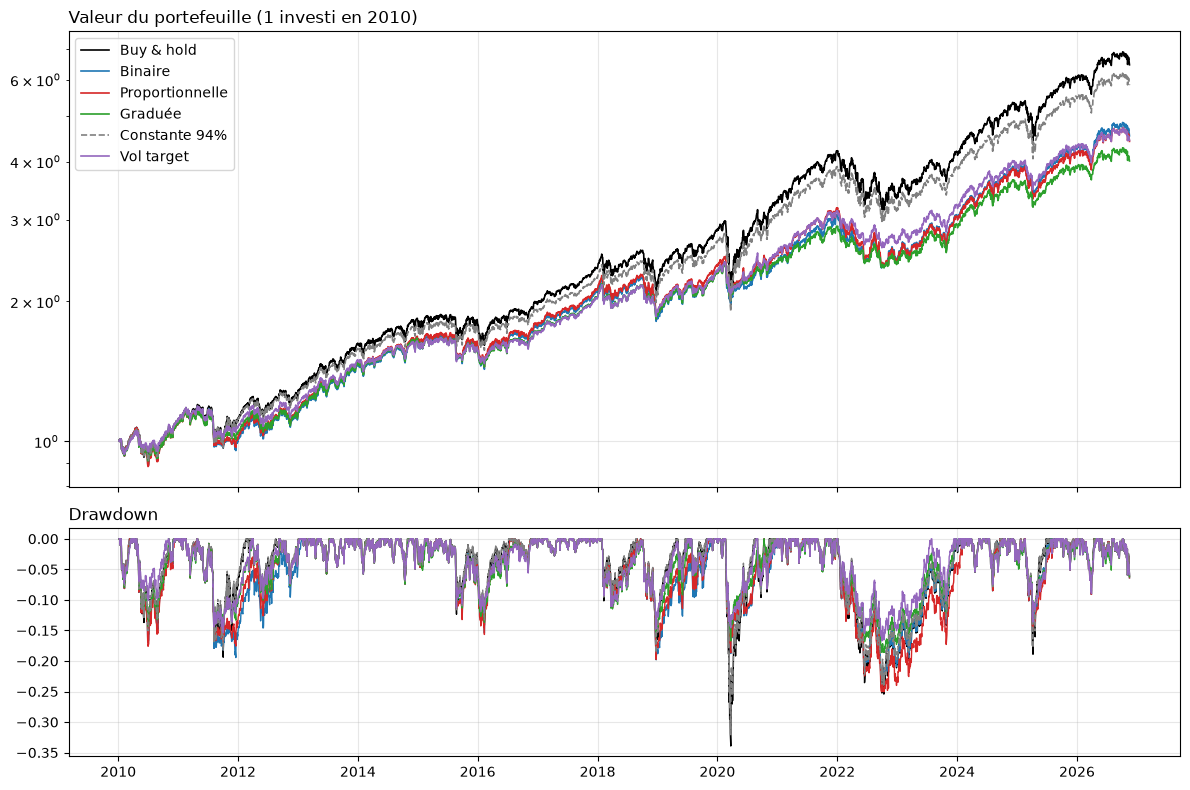

In [5]:
colors = {"Buy & hold": "black", "Binaire": "tab:blue", "Proportionnelle": "tab:red",
          "Graduée": "tab:green", "Vol target": "tab:purple"}

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 8),
                         gridspec_kw={"height_ratios": [2, 1]})

for name, rets in results.items():
    value = (1 + rets).cumprod()
    color = colors.get(name, "gray")
    style = "--" if name.startswith("Constante") else "-"
    axes[0].plot(value.index, value, label=name, color=color, linestyle=style, linewidth=1.2)
    axes[1].plot(value.index, value / value.cummax() - 1, color=color, linestyle=style, linewidth=1)

axes[0].set_yscale("log")
axes[0].set_title(f"Valeur du portefeuille (1 investi en {idx[0].year})", loc="left")
axes[0].legend(loc="upper left")
axes[1].set_title("Drawdown", loc="left")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5.4 Année par année

In [6]:
by_year = annual_returns(results)
by_year.style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None, vmin=-0.3, vmax=0.3)

,Buy & hold,Binaire,Proportionnelle,Graduée,Constante 94%,Vol target
Date,,,,,,
2010,10.7%,9.4%,8.5%,8.7%,10.1%,10.7%
2011,-0.0%,-8.9%,-6.7%,-4.3%,0.2%,-3.4%
2012,13.4%,13.4%,13.4%,9.5%,12.6%,10.3%
2013,29.6%,29.6%,29.6%,29.6%,27.6%,27.0%
2014,11.4%,11.4%,11.4%,11.4%,10.7%,8.3%
2015,-0.7%,-2.1%,-2.5%,-4.5%,-0.6%,-2.8%
2016,9.5%,9.5%,9.6%,8.5%,9.0%,7.4%
2017,19.4%,19.4%,19.4%,19.4%,18.1%,19.4%
2018,-6.2%,-11.6%,-10.3%,-7.3%,-5.8%,-5.3%


## 5.5 Le problème des crises en V

Les stratégies de régimes perdent surtout du terrain lors des crises brèves suivies d'un rebond violent (2011, 2018, 2020, 2025) : le modèle reste défensif pendant le rebond, parce que la volatilité met du temps à retomber. On le voit en zoomant sur 2020.

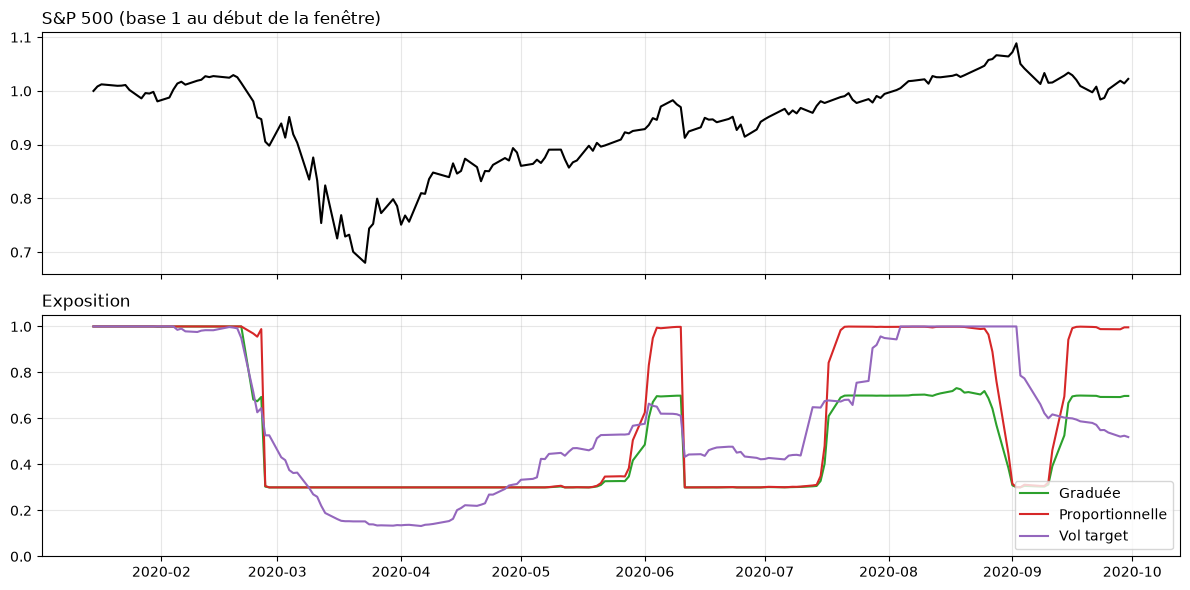

In [7]:
start, end = "2020-01-15", "2020-09-30"
zoom = slice(start, end)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
price = np.exp(df["ret"].cumsum()).loc[zoom]
axes[0].plot(price.index, price / price.iloc[0], color="black")
axes[0].set_title("S&P 500 (base 1 au début de la fenêtre)", loc="left")

for name in ["Graduée", "Proportionnelle", "Vol target"]:
    axes[1].plot(exposures[name].loc[zoom].index, exposures[name].loc[zoom],
                 label=name, color=colors[name])
axes[1].set_title("Exposition", loc="left")
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc="lower right")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5.6 Sensibilité aux coûts de transaction

In [8]:
rows = {}
for cost in [0, 0.0005, 0.001, 0.002]:
    for name in ["Binaire", "Proportionnelle", "Graduée", "Vol target"]:
        m = metrics(backtest(exposures[name], r, cost), exposures[name])
        rows[(f"{cost * 1e4:.0f} pb", name)] = {"Rendement": m["Rendement annualisé"], "Sharpe": m["Sharpe"]}

pd.DataFrame(rows).T.unstack().style.format("{:.2f}")

## Conclusions

À compléter avec tes chiffres après exécution. Les résultats obtenus lors de la première version :

- les stratégies de régimes **divisent à peu près par deux le max drawdown** (environ −34 % → −18 %) ;
- elles coûtent environ **2 à 2,5 % de rendement annualisé** face au buy & hold ;
- la sous-performance se concentre sur les **crises en V** (2011, 2018, 2020, 2025), où le modèle reste défensif pendant le rebond ;
- **2022**, baisse lente sans krach, est le cas où le modèle apporte le plus.

La question ouverte : à volatilité égale, le HMM fait-il mieux que le vol target ? La réponse est dans le tableau 5.2.